In [299]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy.stats import randint, uniform
from sklearn.model_selection import train_test_split,KFold, RandomizedSearchCV
from scipy.stats import randint, uniform
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier 

from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.metrics import ( accuracy_score, classification_report, confusion_matrix, average_precision_score,recall_score,precision_score,f1_score )
import os


In [300]:
df=pd.read_csv("dataset\diabetes_dataset.csv")
df

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
C:\Users\HadZ\AppData\Local\Temp\ipykernel_14424\975894201.py:1: SyntaxWarning: invalid escape sequence '\d'
  df=pd.read_csv("dataset\diabetes_dataset.csv")


,age,gender,ethnicity,education_level,income_level,employment_status,smoking_status,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,...,hdl_cholesterol,ldl_cholesterol,triglycerides,glucose_fasting,glucose_postprandial,insulin_level,hba1c,diabetes_risk_score,diabetes_stage,diagnosed_diabetes
0,58,Male,Asian,Highschool,Lower-Middle,Employed,Never,0,215,5.7,...,41,160,145,136,236,6.36,8.18,29.6,Type 2,1
1,48,Female,White,Highschool,Middle,Employed,Former,1,143,6.7,...,55,50,30,93,150,2.00,5.63,23.0,No Diabetes,0
2,60,Male,Hispanic,Highschool,Middle,Unemployed,Never,1,57,6.4,...,66,99,36,118,195,5.07,7.51,44.7,Type 2,1
3,74,Female,Black,Highschool,Low,Retired,Never,0,49,3.4,...,50,79,140,139,253,5.28,9.03,38.2,Type 2,1
4,46,Male,White,Graduate,Middle,Retired,Never,1,109,7.2,...,52,125,160,137,184,12.74,7.20,23.5,Type 2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,46,Male,Other,Graduate,Upper-Middle,Unemployed,Former,1,136,8.3,...,45,150,116,113,109,14.58,5.55,26.0,Pre-Diabetes,0
99996,41,Female,White,Graduate,Middle,Employed,Never,3,76,8.8,...,55,123,146,96,146,9.02,5.97,24.4,Pre-Diabetes,0
99997,57,Female,Black,No formal,Upper-Middle,Employed,Former,4,121,9.9,...,50,111,184,93,132,2.57,5.21,27.6,No Diabetes,0
99998,47,Female,Black,Highschool,Lower-Middle,Retired,Never,3,52,5.9,...,68,91,116,106,117,9.81,5.53,26.4,Pre-Diabetes,0


In [301]:
df["screen/sleep"]=df["screen_time_hours_per_day"]/df["sleep_hours_per_day"]
df["family_history_diabetes * age"]=df["family_history_diabetes"]*df["age"]


In [302]:
df=df.drop(columns=["employment_status","ethnicity","education_level","sleep_hours_per_day","screen_time_hours_per_day"])

In [303]:
df["hba1c_high"] = (df["hba1c"] >= 6.5).astype(int)
df["fasting_glucose_high"] = (df["glucose_fasting"] >= 126).astype(int)
df["postprandial_glucose_high"] = (df["glucose_postprandial"] >= 200).astype(int)

In [304]:
df.head()

,age,gender,income_level,smoking_status,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,family_history_diabetes,hypertension_history,cardiovascular_history,...,insulin_level,hba1c,diabetes_risk_score,diabetes_stage,diagnosed_diabetes,screen/sleep,family_history_diabetes * age,hba1c_high,fasting_glucose_high,postprandial_glucose_high
0,58,Male,Lower-Middle,Never,0,215,5.7,0,0,0,...,6.36,8.18,29.6,Type 2,1,1.000000,0,1,1,1
1,48,Female,Middle,Former,1,143,6.7,0,0,0,...,2.00,5.63,23.0,No Diabetes,0,1.338462,0,0,0,0
2,60,Male,Middle,Never,1,57,6.4,1,0,0,...,5.07,7.51,44.7,Type 2,1,0.810000,60,1,0,0
3,74,Female,Low,Never,0,49,3.4,0,0,0,...,5.28,9.03,38.2,Type 2,1,0.787879,0,1,1,1
4,46,Male,Middle,Never,1,109,7.2,0,0,0,...,12.74,7.20,23.5,Type 2,1,0.675676,0,1,1,0


In [305]:
df.describe()

,age,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,family_history_diabetes,hypertension_history,cardiovascular_history,bmi,waist_to_hip_ratio,systolic_bp,...,glucose_postprandial,insulin_level,hba1c,diabetes_risk_score,diagnosed_diabetes,screen/sleep,family_history_diabetes * age,hba1c_high,fasting_glucose_high,postprandial_glucose_high
count,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000
mean,50.12041,2.003670,118.911640,5.994787,0.219410,0.250800,0.079200,25.612653,0.856078,115.799610,...,160.035050,9.061242,6.520776,30.222362,0.599980,0.879259,10.978340,0.51105,0.145280,0.101930
std,15.60460,1.417779,84.409662,1.780954,0.413849,0.433476,0.270052,3.586705,0.046837,14.284073,...,30.935472,4.954060,0.813921,9.061505,0.489904,0.395738,21.950623,0.49988,0.352385,0.302558
min,18.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,15.000000,0.670000,90.000000,...,70.000000,2.000000,4.000000,2.700000,0.000000,0.050000,0.000000,0.00000,0.000000,0.000000
25%,39.00000,1.000000,57.000000,4.800000,0.000000,0.000000,0.000000,23.200000,0.820000,106.000000,...,139.000000,5.090000,5.970000,23.800000,0.000000,0.606061,0.000000,0.00000,0.000000,0.000000
50%,50.00000,2.000000,100.000000,6.000000,0.000000,0.000000,0.000000,25.600000,0.860000,116.000000,...,160.000000,8.790000,6.520000,29.000000,1.000000,0.857143,0.000000,1.00000,0.000000,0.000000
75%,61.00000,3.000000,160.000000,7.200000,0.000000,1.000000,0.000000,28.000000,0.890000,125.000000,...,181.000000,12.450000,7.070000,35.600000,1.000000,1.122449,0.000000,1.00000,0.000000,0.000000
max,90.00000,10.000000,833.000000,10.000000,1.000000,1.000000,1.000000,39.200000,1.060000,179.000000,...,287.000000,32.220000,9.800000,67.200000,1.000000,3.666667,90.000000,1.00000,1.000000,1.000000


In [306]:
df.shape

(100000, 31)

In [307]:
df.isna().sum()

age                                   0
gender                                0
income_level                          0
smoking_status                        0
alcohol_consumption_per_week          0
physical_activity_minutes_per_week    0
diet_score                            0
family_history_diabetes               0
hypertension_history                  0
cardiovascular_history                0
bmi                                   0
waist_to_hip_ratio                    0
systolic_bp                           0
diastolic_bp                          0
heart_rate                            0
cholesterol_total                     0
hdl_cholesterol                       0
ldl_cholesterol                       0
triglycerides                         0
glucose_fasting                       0
glucose_postprandial                  0
insulin_level                         0
hba1c                                 0
diabetes_risk_score                   0
diabetes_stage                        0


In [308]:
for i in df.columns:
    
    print(df[i].value_counts().head())
    print("*"*100)

age
52    2517
51    2510
49    2494
53    2482
50    2476
Name: count, dtype: int64
****************************************************************************************************
gender
Female    50216
Male      47771
Other      2013
Name: count, dtype: int64
****************************************************************************************************
income_level
Middle          35152
Lower-Middle    25150
Upper-Middle    19866
Low             14830
High             5002
Name: count, dtype: int64
****************************************************************************************************
smoking_status
Never      59813
Current    20176
Former     20011
Name: count, dtype: int64
****************************************************************************************************
alcohol_consumption_per_week
2    27119
1    26995
3    17896
0    13535
4     9128
Name: count, dtype: int64
*******************************************************************************

In [309]:
df.columns

Index(['age', 'gender', 'income_level', 'smoking_status',
       'alcohol_consumption_per_week', 'physical_activity_minutes_per_week',
       'diet_score', 'family_history_diabetes', 'hypertension_history',
       'cardiovascular_history', 'bmi', 'waist_to_hip_ratio', 'systolic_bp',
       'diastolic_bp', 'heart_rate', 'cholesterol_total', 'hdl_cholesterol',
       'ldl_cholesterol', 'triglycerides', 'glucose_fasting',
       'glucose_postprandial', 'insulin_level', 'hba1c', 'diabetes_risk_score',
       'diabetes_stage', 'diagnosed_diabetes', 'screen/sleep',
       'family_history_diabetes * age', 'hba1c_high', 'fasting_glucose_high',
       'postprandial_glucose_high'],
      dtype='object')

In [310]:
num_cols=df.select_dtypes(include=['number']).columns.tolist()
cat_cols=df.select_dtypes(exclude=['number']).columns.tolist()

In [311]:
df.shape

(100000, 31)

In [312]:
dup=df.duplicated()
print(dup.sum())
# df=df.drop_duplicates()

0


In [313]:
# plt.figure(figsize=(10,13))
# sns.heatmap(
#     df[num_cols].corr(),
#     center=0,
#     cmap="coolwarm"
# )

In [314]:
corr=df[num_cols].corr().abs()

In [315]:
to_drop = [col for col in corr.columns if any((corr[col] > 0.85) & (corr[col] < 1.0) & (corr.index < col))]

In [316]:
df=df.drop(columns=to_drop)

In [317]:
df.shape

(100000, 28)

In [318]:
# for i in df.columns:
        
#     plt.Figure(figsize=(5,7))
#     sns.histplot(data=df,bins=60, kde=True,x=df[i])
#     plt.show()

In [319]:
df.head()

,age,gender,income_level,smoking_status,alcohol_consumption_per_week,physical_activity_minutes_per_week,diet_score,family_history_diabetes,hypertension_history,cardiovascular_history,...,glucose_fasting,glucose_postprandial,insulin_level,diabetes_risk_score,diabetes_stage,diagnosed_diabetes,screen/sleep,hba1c_high,fasting_glucose_high,postprandial_glucose_high
0,58,Male,Lower-Middle,Never,0,215,5.7,0,0,0,...,136,236,6.36,29.6,Type 2,1,1.000000,1,1,1
1,48,Female,Middle,Former,1,143,6.7,0,0,0,...,93,150,2.00,23.0,No Diabetes,0,1.338462,0,0,0
2,60,Male,Middle,Never,1,57,6.4,1,0,0,...,118,195,5.07,44.7,Type 2,1,0.810000,1,0,0
3,74,Female,Low,Never,0,49,3.4,0,0,0,...,139,253,5.28,38.2,Type 2,1,0.787879,1,1,1
4,46,Male,Middle,Never,1,109,7.2,0,0,0,...,137,184,12.74,23.5,Type 2,1,0.675676,1,1,0


data is decent!! 

In [320]:
X=df.drop(columns=["diagnosed_diabetes","diabetes_stage","diabetes_risk_score"])
y=df["diagnosed_diabetes"]

In [321]:
X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    random_state=42,
    stratify=y,
    test_size=0.25,
    
)

In [322]:
num_cols=X_train.select_dtypes(include=['number']).columns.tolist()
cat_cols=X_train.select_dtypes(exclude=['number']).columns.tolist()

num_pipe=Pipeline(
    [
        ("scalar", StandardScaler())
        
    ]
)
cat_pipe=Pipeline(
    [
        ("ohc", OneHotEncoder())
    ]
)
preprocess=ColumnTransformer(
    transformers=[
        ("num",num_pipe,num_cols),
        ("cat",cat_pipe,cat_cols)
    ]

)

In [323]:
base_pipeline_model=Pipeline(
    [
        ("preprocess",preprocess),
        ("model",LogisticRegression())
    ]
)

In [324]:
# base_pipeline_model.fit(X_train,y_train)

In [325]:
# train_pred_base=base_pipeline_model.predict(X_train)
# test_pred_base=base_pipeline_model.predict(X_test)


In [ ]:
# print(classification_report(y_train,train_pred_base))
# print("*"*100)
# print(classification_report(y_test,test_pred_base))

In [327]:
models={
    "Decision_tree": DecisionTreeClassifier(random_state=42),
    "Support_vector": SVC(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier()
}

In [328]:
k=5
cv=KFold(n_splits=k,shuffle=True,random_state=42)

In [329]:
# for name,model, in models.items():
#     recall_scores=[]
#     f1_scores=[]
#     for tr_idx,te_idx in cv.split(X_train,y_train):
#         X_tr,X_te=X_train.iloc[tr_idx],X_train.iloc[te_idx]
#         y_tr,y_te=y_train.iloc[tr_idx],y_train.iloc[te_idx]

#         pipeline=Pipeline(
#             [
#                 ("transform", preprocess),
#                 ("model",model)
#             ]
#         )
#         pipeline.fit(X_tr,y_tr)
#         pred = pipeline.predict(X_te)
    
#         recall_scores.append(round(recall_score(y_te, pred), 2))
#         f1_scores.append(round(f1_score(y_te, pred), 2))
    
#     print("Model name:", name)
#     print("Recall values:", recall_scores)
#     print("F1 scores:", f1_scores)
#     print("\nCV Recall mean:", round(float(np.mean(recall_scores)), 4))
#     print("CV F1 Score mean:", round(float(np.mean(f1_scores)), 4))
#     print("-"*50)

final model is Random Forest

In [330]:
final_model=Pipeline(
    [
        ("transform",preprocess),
       
        ("model", RandomForestClassifier( random_state=42))
    ]
)

In [331]:
param_dist = {
    "model__n_estimators": randint(400, 1200),
    "model__max_depth": [3, 4, 5, 6],
    "model__min_samples_split": randint(10, 40),
    "model__min_samples_leaf": randint(4, 20),
    "model__max_features": [0.25, 0.35, 0.5, "sqrt"],
    "model__bootstrap": [True],
    "model__max_samples": uniform(0.6, 0.35),
    "model__ccp_alpha": uniform(0.0, 0.02),
}

In [332]:
random_search=RandomizedSearchCV(
    cv=cv,
    estimator=final_model,
    n_iter=80,
    n_jobs=-1,
    random_state=42,
    verbose=True,
    scoring="recall",
    param_distributions=param_dist

)

In [333]:
# random_search.fit(X_train,y_train)

In [334]:
# random_search.best_params_

final model

In [339]:
final_pipeline=Pipeline(
    [
        
        ("preprocess", preprocess),
        ("model", RandomForestClassifier(
        bootstrap= True,
        ccp_alpha=np.float64(0.00046124850082831517),
        max_depth= 5,
        max_features= 0.5,
        max_samples= np.float64(0.7399513401003394),
        min_samples_leaf=19,
        min_samples_split= 37,
        n_estimators= 1099,
        class_weight="balanced"
        ))
    ]
)

In [340]:
final_pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](25,)","['age','gender','income_level',...,'hba1c_high','fasting_glucose_high', 'postprandial_glucose_high']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,25
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``rema

In [341]:
y_pred_train=final_pipeline.predict(X_train)

y_pred_test=final_pipeline.predict(X_test)

In [342]:
print(classification_report(y_train,y_pred_train))
print("*"*100)
print(classification_report(y_test,y_pred_test))

              precision    recall  f1-score   support

           0       0.84      1.00      0.91     30001
           1       1.00      0.87      0.93     44999

    accuracy                           0.92     75000
   macro avg       0.92      0.93      0.92     75000
weighted avg       0.93      0.92      0.92     75000

****************************************************************************************************
              precision    recall  f1-score   support

           0       0.83      1.00      0.91     10001
           1       1.00      0.87      0.93     14999

    accuracy                           0.92     25000
   macro avg       0.92      0.93      0.92     25000
weighted avg       0.93      0.92      0.92     25000



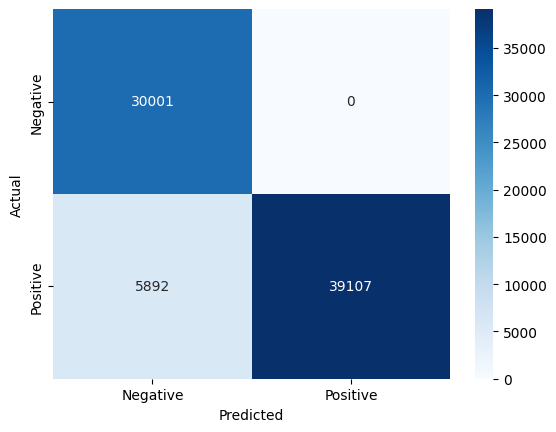

In [344]:
cm = confusion_matrix(y_train, y_pred_train)


sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=["Negative", "Positive"], 
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

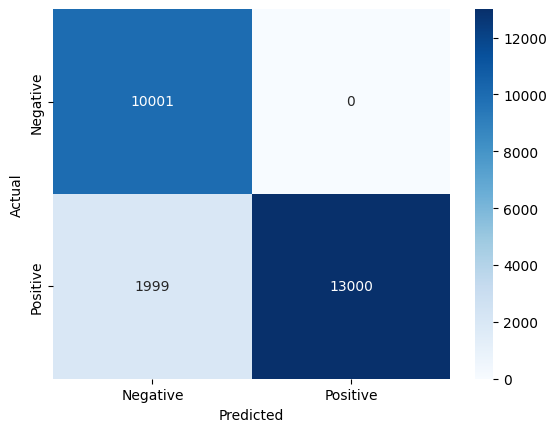

In [343]:
cm = confusion_matrix(y_test, y_pred_test)


sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=["Negative", "Positive"], 
            yticklabels=["Negative", "Positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()